In [ ]:
!pip install openmeteo-requests requests-cache retry-requests numpy pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.7/890.7 kB 23.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 67.1 MB/s  0:00:00
  Attempting uninstall: flatbuffers
    Found existing installation: flatbuffers 25.12.19
    Uninstalling flatbuffers-25.12.19:
      Successfully uninstalled flatbuffers-25.12.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [openmeteo-requests]


In [ ]:
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
  "latitude": 33.5138,
  "longitude": 36.2765,
  "start_date": "2001-01-01",
  "end_date": "2025-12-31",
  "daily": ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "precipitation_sum", "et0_fao_evapotranspiration"],
  "hourly": "temperature_2m",
  "timezone": "auto",
}
responses = openmeteo.weather_api(url, params = params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates: {abs(response.Latitude())}°{'S' if response.Latitude() < 0 else 'N'} {abs(response.Longitude())}°{'W' if response.Longitude() < 0 else 'E'}")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone: {response.Timezone()}{response.TimezoneAbbreviation()}")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process hourly data. The order of variables needs to be the same as requested.
hourly = response.Hourly()
hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()

hourly_data = {
  "date": pd.date_range(
    start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
    end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
    freq = pd.Timedelta(seconds = hourly.Interval()),
    inclusive = "left"
  ).tz_convert(response.Timezone().decode())
}

hourly_data["temperature_2m"] = hourly_temperature_2m

hourly_dataframe = pd.DataFrame(data = hourly_data)
print("\nHourly data\n", hourly_dataframe)

# Process daily data. The order of variables needs to be the same as requested.
daily = response.Daily()
daily_temperature_2m_mean = daily.Variables(0).ValuesAsNumpy()
daily_temperature_2m_max = daily.Variables(1).ValuesAsNumpy()
daily_temperature_2m_min = daily.Variables(2).ValuesAsNumpy()
daily_precipitation_sum = daily.Variables(3).ValuesAsNumpy()
daily_et0_fao_evapotranspiration = daily.Variables(4).ValuesAsNumpy()

daily_data = {
  "date": pd.date_range(
    start = pd.to_datetime(daily.Time(), unit = "s", utc = True),
    end =  pd.to_datetime(daily.TimeEnd(), unit = "s", utc = True),
    freq = pd.Timedelta(seconds = daily.Interval()),
    inclusive = "left"
  ).tz_convert(response.Timezone().decode())
}

daily_data["temperature_2m_mean"] = daily_temperature_2m_mean
daily_data["temperature_2m_max"] = daily_temperature_2m_max
daily_data["temperature_2m_min"] = daily_temperature_2m_min
daily_data["precipitation_sum"] = daily_precipitation_sum
daily_data["et0_fao_evapotranspiration"] = daily_et0_fao_evapotranspiration

daily_dataframe = pd.DataFrame(data = daily_data)
print("\nDaily data\n", daily_dataframe)

Coordinates: 33.49736404418945°N 36.3118782043457°E
Elevation: 693.0 m asl
Timezone: b'Asia/Damascus'b'GMT+3'
Timezone difference to GMT+0: 10800s

Hourly data
                             date  temperature_2m
0      2000-12-31 23:00:00+02:00           6.014
1      2001-01-01 00:00:00+02:00           4.914
2      2001-01-01 01:00:00+02:00           3.114
3      2001-01-01 02:00:00+02:00           2.214
4      2001-01-01 03:00:00+02:00           1.964
...                          ...             ...
219139 2025-12-31 19:00:00+03:00          11.250
219140 2025-12-31 20:00:00+03:00          11.000
219141 2025-12-31 21:00:00+03:00          10.400
219142 2025-12-31 22:00:00+03:00          10.350
219143 2025-12-31 23:00:00+03:00          10.400

[219144 rows x 2 columns]

Daily data
                           date  temperature_2m_mean  temperature_2m_max  \
0    2000-12-31 23:00:00+02:00             6.997334           13.031605   
1    2001-01-01 23:00:00+02:00             7.580667          

In [ ]:
daily_dataframe.to_csv(
    "damascus_weather_2001_2025.csv",
    index=False
)

from google.colab import files
files.download("damascus_weather_2001_2025.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import pandas as pd
from google.colab import files

# Upload the historical weather CSV file
uploaded = files.upload()

# Read the uploaded file
file_name = next(iter(uploaded))
weather_df = pd.read_csv(file_name)

# Convert date column
weather_df["date"] = pd.to_datetime(weather_df["date"])

# Display basic information
print("Dataset shape:", weather_df.shape)
print("\nColumns:")
print(weather_df.columns.tolist())

print("\nMissing values:")
print(weather_df.isnull().sum())

print("\nDuplicate rows:", weather_df.duplicated().sum())

print("\nStatistical summary:")
display(weather_df.describe())

Saving damascus_weather_2001_2025.csv to damascus_weather_2001_2025.csv
Dataset shape: (9131, 6)

Columns:
['date', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'et0_fao_evapotranspiration']

Missing values:
date                          0
temperature_2m_mean           0
temperature_2m_max            0
temperature_2m_min            0
precipitation_sum             0
et0_fao_evapotranspiration    0
dtype: int64

Duplicate rows: 0

Statistical summary:


/tmp/ipykernel_418/3793360780.py:12: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  weather_df["date"] = pd.to_datetime(weather_df["date"])


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,et0_fao_evapotranspiration
count,9131.000000,9131.000000,9131.000000,9131.000000,9131.000000
mean,17.881688,24.825712,10.890141,0.466860,4.567015
std,8.270953,9.503549,6.869373,1.925441,2.366552
min,-7.015167,0.692340,-15.520397,0.000000,0.373521
25%,10.438542,16.348897,5.236012,0.000000,2.289140
50%,18.510416,25.604687,11.298998,0.000000,4.419186
75%,25.283333,33.402384,16.510308,0.000000,6.712262
max,37.004170,45.004097,29.984339,33.400000,11.494655


,year,month,rainfall_mm,mean_temperature,et0_mm,water_balance_mm
0,2000,12,0.000000,6.997333,1.737162,-1.737162
1,2001,1,13.500000,6.554255,53.655408,-40.155408
2,2001,2,44.800001,7.507378,59.670234,-14.870234
3,2001,3,6.400000,14.628987,125.601529,-119.201529
4,2001,4,4.500000,17.105737,153.087745,-148.587744
5,2001,5,5.600000,20.526299,183.093785,-177.493785
6,2001,6,0.000000,25.390181,225.450503,-225.450503
7,2001,7,0.000000,27.428315,245.395708,-245.395708
8,2001,8,0.000000,26.904861,208.464401,-208.464401
9,2001,9,0.500000,23.778862,162.234875,-161.734875


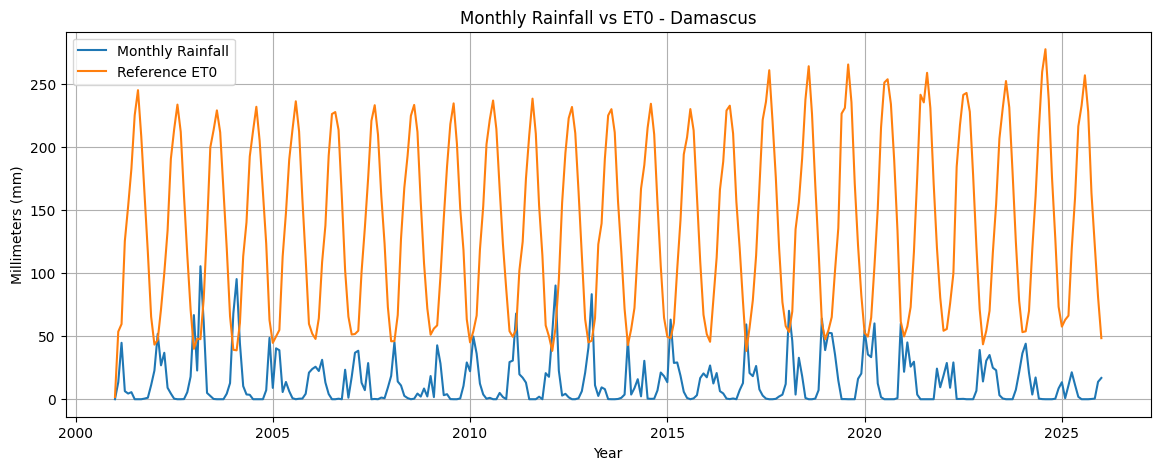

In [4]:
# Fix date format
weather_df["date"] = pd.to_datetime(
    weather_df["date"],
    errors="coerce",
    utc=True
)

# Remove invalid dates if any
weather_df = weather_df.dropna(subset=["date"]).copy()

# Prepare date information
weather_df = weather_df.sort_values("date")
weather_df["year"] = weather_df["date"].dt.year
weather_df["month"] = weather_df["date"].dt.month

# Calculate monthly indicators
monthly_weather = weather_df.groupby(
    ["year", "month"]
).agg(
    rainfall_mm=("precipitation_sum", "sum"),
    mean_temperature=("temperature_2m_mean", "mean"),
    et0_mm=("et0_fao_evapotranspiration", "sum")
).reset_index()

# Calculate water balance
monthly_weather["water_balance_mm"] = (
    monthly_weather["rainfall_mm"] - monthly_weather["et0_mm"]
)

# Display first 12 months
display(monthly_weather.head(12))

# Plot rainfall and ET0
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_weather["year"] + monthly_weather["month"] / 12,
    monthly_weather["rainfall_mm"],
    label="Monthly Rainfall"
)
plt.plot(
    monthly_weather["year"] + monthly_weather["month"] / 12,
    monthly_weather["et0_mm"],
    label="Reference ET0"
)

plt.title("Monthly Rainfall vs ET0 - Damascus")
plt.xlabel("Year")
plt.ylabel("Millimeters (mm)")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# Monthly water deficit analysis

weather_df["date"] = pd.to_datetime(weather_df["date"])

monthly_df = weather_df.set_index("date").resample("ME").agg({
    "precipitation_sum": "sum",
    "temperature_2m_mean": "mean",
    "et0_fao_evapotranspiration": "sum"
}).reset_index()

monthly_df = monthly_df.rename(columns={
    "precipitation_sum": "rainfall_mm",
    "temperature_2m_mean": "mean_temperature",
    "et0_fao_evapotranspiration": "et0_mm"
})

monthly_df["water_balance_mm"] = (
    monthly_df["rainfall_mm"] - monthly_df["et0_mm"]
)

monthly_df["water_deficit"] = (
    monthly_df["water_balance_mm"] < 0
)

monthly_df["year"] = monthly_df["date"].dt.year

annual_drought = monthly_df.groupby("year").agg(
    total_rainfall=("rainfall_mm", "sum"),
    total_et0=("et0_mm", "sum"),
    annual_water_balance=("water_balance_mm", "sum"),
    deficit_months=("water_deficit", "sum")
).reset_index()

display(annual_drought.tail(10))

,year,total_rainfall,total_et0,annual_water_balance,deficit_months
16,2016,151.699998,1658.503499,-1506.803501,11
17,2017,94.900000,1788.796356,-1693.896357,12
18,2018,283.200002,1731.027311,-1447.827310,10
19,2019,247.000006,1746.293506,-1499.293500,11
20,2020,225.900000,1761.989004,-1536.089004,12
21,2021,157.100001,1818.760274,-1661.660273,12
22,2022,127.699999,1761.139352,-1633.439354,12
23,2023,182.900001,1754.505039,-1571.605037,12
24,2024,109.100006,1828.460151,-1719.360145,12
25,2025,77.800000,1759.321494,-1681.521494,12


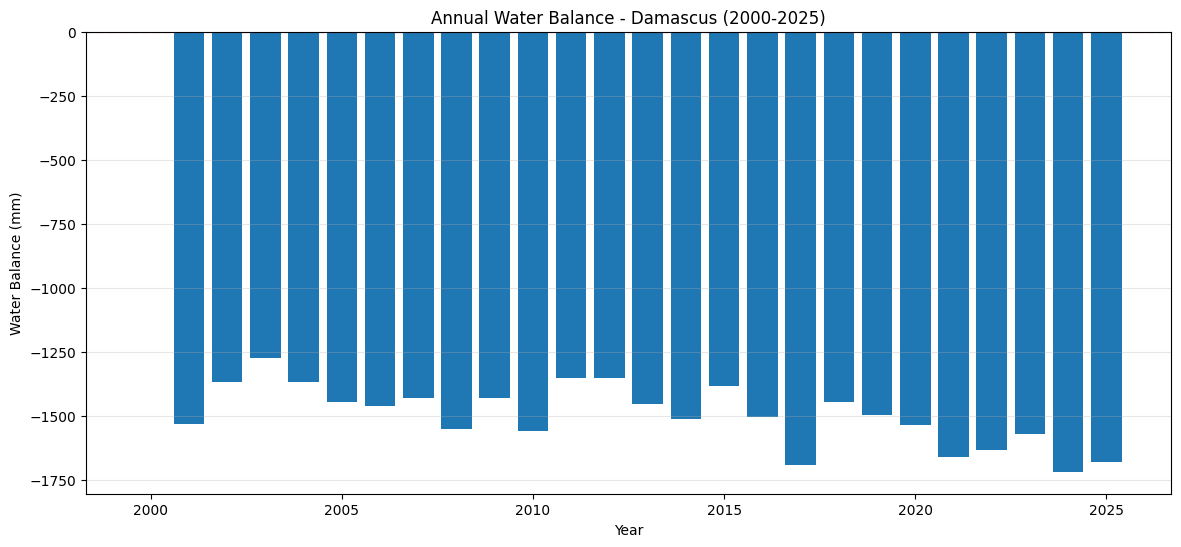

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    annual_drought["year"],
    annual_drought["annual_water_balance"]
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Annual Water Balance - Damascus (2000-2025)")
plt.xlabel("Year")
plt.ylabel("Water Balance (mm)")
plt.grid(axis="y", alpha=0.3)

plt.show()

,year,total_rainfall,total_et0,annual_water_balance,deficit_months
24,2024,109.100006,1828.460151,-1719.360145,12
17,2017,94.900000,1788.796356,-1693.896357,12
25,2025,77.800000,1759.321494,-1681.521494,12
21,2021,157.100001,1818.760274,-1661.660273,12
22,2022,127.699999,1761.139352,-1633.439354,12


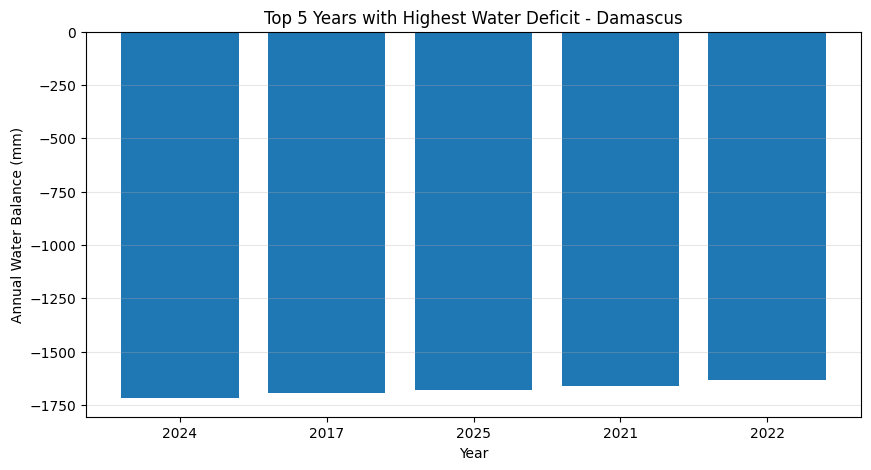

In [8]:
# Identify the 5 years with the highest water deficit

worst_drought_years = annual_drought.sort_values(
    by="annual_water_balance",
    ascending=True
).head(5)

display(worst_drought_years)

# Visualize the results
plt.figure(figsize=(10, 5))

plt.bar(
    worst_drought_years["year"].astype(str),
    worst_drought_years["annual_water_balance"]
)

plt.title("Top 5 Years with Highest Water Deficit - Damascus")
plt.xlabel("Year")
plt.ylabel("Annual Water Balance (mm)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [9]:
# Check date coverage and data completeness

weather_df["date"] = pd.to_datetime(
    weather_df["date"], errors="coerce"
)

print("First date:", weather_df["date"].min())
print("Last date:", weather_df["date"].max())

print("\nRecords per year:")
yearly_check = weather_df.groupby(
    weather_df["date"].dt.year
).agg(
    records=("date", "count"),
    first_date=("date", "min"),
    last_date=("date", "max")
)

display(yearly_check)

print("\nDuplicate dates:",
      weather_df["date"].duplicated().sum())

print("\nMissing values:")
display(weather_df.isnull().sum())

First date: 2000-12-31 21:00:00+00:00
Last date: 2025-12-30 21:00:00+00:00

Records per year:


,records,first_date,last_date
date,,,
2000,1,2000-12-31 21:00:00+00:00,2000-12-31 21:00:00+00:00
2001,365,2001-01-01 21:00:00+00:00,2001-12-31 21:00:00+00:00
2002,365,2002-01-01 21:00:00+00:00,2002-12-31 21:00:00+00:00
2003,365,2003-01-01 21:00:00+00:00,2003-12-31 21:00:00+00:00
2004,366,2004-01-01 21:00:00+00:00,2004-12-31 21:00:00+00:00
2005,365,2005-01-01 21:00:00+00:00,2005-12-31 21:00:00+00:00
2006,365,2006-01-01 21:00:00+00:00,2006-12-31 21:00:00+00:00
2007,365,2007-01-01 21:00:00+00:00,2007-12-31 21:00:00+00:00
2008,366,2008-01-01 21:00:00+00:00,2008-12-31 21:00:00+00:00



Duplicate dates: 0

Missing values:


,0
date,0
temperature_2m_mean,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
et0_fao_evapotranspiration,0
year,0
month,0


In [10]:
# Find missing calendar dates in each year

weather_df["date"] = pd.to_datetime(
    weather_df["date"], errors="coerce"
)

# Remove timezone if present, without shifting the clock
if weather_df["date"].dt.tz is not None:
    weather_df["date"] = weather_df["date"].dt.tz_localize(None)

weather_df["date"] = weather_df["date"].dt.normalize()

all_dates = pd.date_range(
    start=weather_df["date"].min(),
    end=weather_df["date"].max(),
    freq="D"
)

missing_dates = all_dates.difference(
    weather_df["date"]
)

print("Total missing calendar dates:", len(missing_dates))
print("\nMissing dates:")
print(missing_dates)

print("\nRecords per year:")
print(weather_df.groupby(
    weather_df["date"].dt.year
).size())

Total missing calendar dates: 0

Missing dates:
DatetimeIndex([], dtype='datetime64[ns]', freq='D')

Records per year:
date
2000      1
2001    365
2002    365
2003    365
2004    366
2005    365
2006    365
2007    365
2008    366
2009    365
2010    365
2011    365
2012    366
2013    365
2014    365
2015    365
2016    366
2017    365
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
2025    364
dtype: int64


In [13]:
# Show all available DataFrame variables
import pandas as pd

for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)

weather_df (9131, 8)
monthly_weather (301, 6)
monthly_df (301, 7)
annual_drought (26, 5)
worst_drought_years (5, 5)
yearly_check (26, 3)


In [14]:
print("Columns:")
print(monthly_df.columns.tolist())

print("\nFirst 12 records:")
display(monthly_df.head(12))

print("\nShape:")
print(monthly_df.shape)

Columns:
['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm', 'water_deficit', 'year']

First 12 records:


,date,rainfall_mm,mean_temperature,et0_mm,water_balance_mm,water_deficit,year
0,2000-12-31 00:00:00+00:00,0.000000,6.997333,1.737162,-1.737162,True,2000
1,2001-01-31 00:00:00+00:00,13.500000,6.554255,53.655408,-40.155408,True,2001
2,2001-02-28 00:00:00+00:00,44.800001,7.507378,59.670234,-14.870234,True,2001
3,2001-03-31 00:00:00+00:00,6.400000,14.628987,125.601529,-119.201529,True,2001
4,2001-04-30 00:00:00+00:00,4.500000,17.105737,153.087745,-148.587744,True,2001
5,2001-05-31 00:00:00+00:00,5.600000,20.526299,183.093785,-177.493785,True,2001
6,2001-06-30 00:00:00+00:00,0.000000,25.390181,225.450503,-225.450503,True,2001
7,2001-07-31 00:00:00+00:00,0.000000,27.428315,245.395708,-245.395708,True,2001
8,2001-08-31 00:00:00+00:00,0.000000,26.904861,208.464401,-208.464401,True,2001
9,2001-09-30 00:00:00+00:00,0.500000,23.778862,162.234875,-161.734875,True,2001



Shape:
(301, 7)


In [18]:
print("monthly_df columns:")
for col in monthly_df.columns:
    print(repr(col))

print("\nweather_df columns:")
for col in weather_df.columns:
    print(repr(col))

monthly_df columns:
'date'
'rainfall_mm'
'mean_temperature'
'et0_mm'
'water_balance_mm'
'water_deficit'
'year'

weather_df columns:
'date'
'temperature_2m_mean'
'temperature_2m_max'
'temperature_2m_min'
'precipitation_sum'
'et0_fao_evapotranspiration'
'year'
'month'


In [20]:
print("monthly_df columns:")
print(monthly_df.columns.tolist())

print("\nmonthly_df shape:")
print(monthly_df.shape)

monthly_df columns:
['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm', 'water_deficit', 'year']

monthly_df shape:
(301, 7)


In [22]:
print("نوع monthly_df:", type(monthly_df))
print("الأعمدة بالتفصيل:")
for col in monthly_df.columns:
    print(repr(col))

print("\nأول 5 صفوف:")
display(monthly_df.head())

نوع monthly_df: <class 'pandas.core.frame.DataFrame'>
الأعمدة بالتفصيل:
'date'
'rainfall_mm'
'mean_temperature'
'et0_mm'
'water_balance_mm'
'water_deficit'
'year'

أول 5 صفوف:


,date,rainfall_mm,mean_temperature,et0_mm,water_balance_mm,water_deficit,year
0,2000-12-31 00:00:00+00:00,0.000000,6.997333,1.737162,-1.737162,True,2000
1,2001-01-31 00:00:00+00:00,13.500000,6.554255,53.655408,-40.155408,True,2001
2,2001-02-28 00:00:00+00:00,44.800001,7.507378,59.670234,-14.870234,True,2001
3,2001-03-31 00:00:00+00:00,6.400000,14.628987,125.601529,-119.201529,True,2001
4,2001-04-30 00:00:00+00:00,4.500000,17.105737,153.087745,-148.587744,True,2001


In [24]:
annual_test = monthly_df.groupby("year").agg(
    total_rainfall=("rainfall_mm", "sum"),
    total_eto=("et0_mm", "sum"),
    annual_water_balance=("water_balance_mm", "sum"),
    deficit_months=("water_deficit", "sum")
).reset_index()

display(annual_test.tail(10))

print("Annual records:", len(annual_test))

,year,total_rainfall,total_eto,annual_water_balance,deficit_months
16,2016,151.699998,1658.503499,-1506.803501,11
17,2017,94.900000,1788.796356,-1693.896357,12
18,2018,283.200002,1731.027311,-1447.827310,10
19,2019,247.000006,1746.293506,-1499.293500,11
20,2020,225.900000,1761.989004,-1536.089004,12
21,2021,157.100001,1818.760274,-1661.660273,12
22,2022,127.699999,1761.139352,-1633.439354,12
23,2023,182.900001,1754.505039,-1571.605037,12
24,2024,109.100006,1828.460151,-1719.360145,12
25,2025,77.800000,1759.321494,-1681.521494,12


Annual records: 26


In [25]:
# Check the number of monthly records in each year

months_per_year = (
    monthly_df.groupby("year")
    .size()
    .reset_index(name="number_of_months")
)

display(months_per_year)

print("Years with 12 months:",
      (months_per_year["number_of_months"] == 12).sum())

print("Incomplete years:",
      (months_per_year["number_of_months"] < 12).sum())

,year,number_of_months
0,2000,1
1,2001,12
2,2002,12
3,2003,12
4,2004,12
5,2005,12
6,2006,12
7,2007,12
8,2008,12
9,2009,12


Years with 12 months: 25
Incomplete years: 1


In [26]:
incomplete_years = months_per_year[
    months_per_year["number_of_months"] < 12
]

display(incomplete_years)

,year,number_of_months
0,2000,1


In [27]:
# Keep only complete years for annual analysis

complete_years = months_per_year.loc[
    months_per_year["number_of_months"] == 12, "year"
]

monthly_complete = monthly_df[
    monthly_df["year"].isin(complete_years)
].copy()

print("Complete monthly records:", len(monthly_complete))
print("Number of complete years:", monthly_complete["year"].nunique())
print("First year:", monthly_complete["year"].min())
print("Last year:", monthly_complete["year"].max())

Complete monthly records: 300
Number of complete years: 25
First year: 2001
Last year: 2025


In [30]:
# Recreate complete monthly dataset
monthly_complete = monthly_df[
    monthly_df["year"].isin(complete_years)
].copy()

# Annual aggregation
annual_drought = (
    monthly_complete.groupby("year")
    .agg(
        total_rainfall=("rainfall_mm", "sum"),
        total_eto=("et0_mm", "sum"),
        annual_water_balance=("water_balance_mm", "sum"),
        deficit_months=("water_deficit", "sum")
    )
    .reset_index()
)

display(annual_drought.tail(10))

print("Annual records:", len(annual_drought))

,year,total_rainfall,total_eto,annual_water_balance,deficit_months
15,2016,151.699998,1658.503499,-1506.803501,11
16,2017,94.900000,1788.796356,-1693.896357,12
17,2018,283.200002,1731.027311,-1447.827310,10
18,2019,247.000006,1746.293506,-1499.293500,11
19,2020,225.900000,1761.989004,-1536.089004,12
20,2021,157.100001,1818.760274,-1661.660273,12
21,2022,127.699999,1761.139352,-1633.439354,12
22,2023,182.900001,1754.505039,-1571.605037,12
23,2024,109.100006,1828.460151,-1719.360145,12
24,2025,77.800000,1759.321494,-1681.521494,12


Annual records: 25


In [31]:
print("Water balance statistics:")
display(monthly_complete["water_balance_mm"].describe())

print("Negative water balance months:",
      (monthly_complete["water_balance_mm"] < 0).sum())

print("Positive water balance months:",
      (monthly_complete["water_balance_mm"] >= 0).sum())

display(
    monthly_complete[
        ["date", "rainfall_mm", "mean_temperature",
         "water_balance_mm", "water_deficit"]
    ].head(12)
)

Water balance statistics:


,water_balance_mm
count,300.000000
mean,-124.789249
std,83.782811
min,-277.893905
25%,-209.950931
50%,-123.395685
75%,-47.082736
max,57.921462


Negative water balance months: 285
Positive water balance months: 15


,date,rainfall_mm,mean_temperature,water_balance_mm,water_deficit
1,2001-01-31 00:00:00+00:00,13.500000,6.554255,-40.155408,True
2,2001-02-28 00:00:00+00:00,44.800001,7.507378,-14.870234,True
3,2001-03-31 00:00:00+00:00,6.400000,14.628987,-119.201529,True
4,2001-04-30 00:00:00+00:00,4.500000,17.105737,-148.587744,True
5,2001-05-31 00:00:00+00:00,5.600000,20.526299,-177.493785,True
6,2001-06-30 00:00:00+00:00,0.000000,25.390181,-225.450503,True
7,2001-07-31 00:00:00+00:00,0.000000,27.428315,-245.395708,True
8,2001-08-31 00:00:00+00:00,0.000000,26.904861,-208.464401,True
9,2001-09-30 00:00:00+00:00,0.500000,23.778862,-161.734875,True
10,2001-10-31 00:00:00+00:00,1.200000,19.073342,-115.407540,True


In [32]:
print("Missing rainfall values:",
      monthly_complete["rainfall_mm"].isna().sum())

print("Zero rainfall months:",
      (monthly_complete["rainfall_mm"] == 0).sum())

print("Negative rainfall values:",
      (monthly_complete["rainfall_mm"] < 0).sum())

display(
    monthly_complete.loc[
        monthly_complete["rainfall_mm"] == 0,
        ["date", "rainfall_mm", "mean_temperature"]
    ].head(20)
)

Missing rainfall values: 0
Zero rainfall months: 61
Negative rainfall values: 0


,date,rainfall_mm,mean_temperature
6,2001-06-30 00:00:00+00:00,0.0,25.390181
7,2001-07-31 00:00:00+00:00,0.0,27.428315
8,2001-08-31 00:00:00+00:00,0.0,26.904861
19,2002-07-31 00:00:00+00:00,0.0,27.431138
20,2002-08-31 00:00:00+00:00,0.0,25.403114
31,2003-07-31 00:00:00+00:00,0.0,26.341085
32,2003-08-31 00:00:00+00:00,0.0,27.241890
33,2003-09-30 00:00:00+00:00,0.0,22.897195
42,2004-06-30 00:00:00+00:00,0.0,24.265945
43,2004-07-31 00:00:00+00:00,0.0,27.210035


In [33]:
print("Columns:")
print(monthly_complete.columns.tolist())

print("\nDataset shape:")
print(monthly_complete.shape)

print("\nSample data:")
display(monthly_complete.head())

Columns:
['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm', 'water_deficit', 'year']

Dataset shape:
(300, 7)

Sample data:


,date,rainfall_mm,mean_temperature,et0_mm,water_balance_mm,water_deficit,year
1,2001-01-31 00:00:00+00:00,13.500000,6.554255,53.655408,-40.155408,True,2001
2,2001-02-28 00:00:00+00:00,44.800001,7.507378,59.670234,-14.870234,True,2001
3,2001-03-31 00:00:00+00:00,6.400000,14.628987,125.601529,-119.201529,True,2001
4,2001-04-30 00:00:00+00:00,4.500000,17.105737,153.087745,-148.587744,True,2001
5,2001-05-31 00:00:00+00:00,5.600000,20.526299,183.093785,-177.493785,True,2001


In [34]:
# Check drought class distribution
print("Water deficit distribution:")
print(monthly_complete["water_deficit"].value_counts())

print("\nPercentage distribution:")
print(
    monthly_complete["water_deficit"]
    .value_counts(normalize=True) * 100
)

print("\nCheck missing values:")
print(monthly_complete.isnull().sum())

print("\nDate range:")
print(monthly_complete["date"].min())
print(monthly_complete["date"].max())

Water deficit distribution:
water_deficit
True     285
False     15
Name: count, dtype: int64

Percentage distribution:
water_deficit
True     95.0
False     5.0
Name: proportion, dtype: float64

Check missing values:
date                0
rainfall_mm         0
mean_temperature    0
et0_mm              0
water_balance_mm    0
water_deficit       0
year                0
dtype: int64

Date range:
2001-01-31 00:00:00+00:00
2025-12-31 00:00:00+00:00


In [35]:
# Sort data by date
model_df = monthly_complete.copy()
model_df = model_df.sort_values("date").reset_index(drop=True)

# Extract month for seasonal patterns
model_df["month"] = model_df["date"].dt.month

# Target: predict water deficit in the next month
model_df["target_next_month"] = (
    model_df["water_deficit"].shift(-1)
)

# Remove the last row because it has no next-month target
model_df = model_df.dropna(
    subset=["target_next_month"]
).copy()

model_df["target_next_month"] = (
    model_df["target_next_month"].astype(int)
)

print("Prepared dataset:", model_df.shape)

print("\nNext-month target distribution:")
print(model_df["target_next_month"].value_counts())

print("\nTarget percentages:")
print(
    model_df["target_next_month"]
    .value_counts(normalize=True) * 100
)

display(model_df.head())

Prepared dataset: (299, 9)

Next-month target distribution:
target_next_month
1    284
0     15
Name: count, dtype: int64

Target percentages:
target_next_month
1    94.983278
0     5.016722
Name: proportion, dtype: float64


,date,rainfall_mm,mean_temperature,et0_mm,water_balance_mm,water_deficit,year,month,target_next_month
0,2001-01-31 00:00:00+00:00,13.500000,6.554255,53.655408,-40.155408,True,2001,1,1
1,2001-02-28 00:00:00+00:00,44.800001,7.507378,59.670234,-14.870234,True,2001,2,1
2,2001-03-31 00:00:00+00:00,6.400000,14.628987,125.601529,-119.201529,True,2001,3,1
3,2001-04-30 00:00:00+00:00,4.500000,17.105737,153.087745,-148.587744,True,2001,4,1
4,2001-05-31 00:00:00+00:00,5.600000,20.526299,183.093785,-177.493785,True,2001,5,1


In [36]:
# Chronological train-test split
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTraining target distribution:")
print(train_df["target_next_month"].value_counts())

print("\nTesting target distribution:")
print(test_df["target_next_month"].value_counts())

Training period:
2001-01-31 00:00:00+00:00 to 2020-11-30 00:00:00+00:00

Testing period:
2020-12-31 00:00:00+00:00 to 2025-11-30 00:00:00+00:00

Training target distribution:
target_next_month
1    224
0     15
Name: count, dtype: int64

Testing target distribution:
target_next_month
1    60
Name: count, dtype: int64


In [37]:
print("TRAIN SET")
print(train_df["target_next_month"].value_counts())
print(train_df["target_next_month"].value_counts(normalize=True) * 100)

print("\nTEST SET")
print(test_df["target_next_month"].value_counts())
print(test_df["target_next_month"].value_counts(normalize=True) * 100)

print("\nMissing target values:")
print("Train:", train_df["target_next_month"].isna().sum())
print("Test:", test_df["target_next_month"].isna().sum())

TRAIN SET
target_next_month
1    224
0     15
Name: count, dtype: int64
target_next_month
1    93.723849
0     6.276151
Name: proportion, dtype: float64

TEST SET
target_next_month
1    60
Name: count, dtype: int64
target_next_month
1    100.0
Name: proportion, dtype: float64

Missing target values:
Train: 0
Test: 0


In [41]:
print("Available DataFrames:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape, obj.columns.tolist())

Available DataFrames:
weather_df (9131, 8) ['date', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'et0_fao_evapotranspiration', 'year', 'month']
monthly_weather (301, 6) ['year', 'month', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm']
monthly_df (301, 7) ['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm', 'water_deficit', 'year']
annual_drought (25, 5) ['year', 'total_rainfall', 'total_eto', 'annual_water_balance', 'deficit_months']
worst_drought_years (5, 5) ['year', 'total_rainfall', 'total_et0', 'annual_water_balance', 'deficit_months']
yearly_check (26, 3) ['records', 'first_date', 'last_date']
data (300, 7) ['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm', 'water_deficit', 'year']
annual_test (26, 5) ['year', 'total_rainfall', 'total_eto', 'annual_water_balance', 'deficit_months']
months_per_year (26, 2) ['year', 'number_of_months']
incomplete_years (1, 2) ['year', 'number_of_

In [42]:
print("Target distribution by year:")

print(
    model_df.groupby("year")["target_next_month"]
    .value_counts()
    .unstack(fill_value=0)
)

Target distribution by year:
target_next_month  0   1
year                    
2001               1  11
2002               1  11
2003               3   9
2004               0  12
2005               0  12
2006               0  12
2007               0  12
2008               0  12
2009               0  12
2010               0  12
2011               2  10
2012               2  10
2013               1  11
2014               1  11
2015               0  12
2016               1  11
2017               1  11
2018               1  11
2019               1  11
2020               0  12
2021               0  12
2022               0  12
2023               0  12
2024               0  12
2025               0  11


In [44]:
# Check available datasets and their sizes

import pandas as pd

print("AVAILABLE DATASETS")
print("-" * 50)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataset: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

AVAILABLE DATASETS
--------------------------------------------------

Dataset: weather_df
Shape: (9131, 8)
Columns: ['date', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'et0_fao_evapotranspiration', 'year', 'month']

Dataset: monthly_weather
Shape: (301, 6)
Columns: ['year', 'month', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm']

Dataset: monthly_df
Shape: (301, 7)
Columns: ['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm', 'water_deficit', 'year']

Dataset: annual_drought
Shape: (25, 5)
Columns: ['year', 'total_rainfall', 'total_eto', 'annual_water_balance', 'deficit_months']

Dataset: worst_drought_years
Shape: (5, 5)
Columns: ['year', 'total_rainfall', 'total_et0', 'annual_water_balance', 'deficit_months']

Dataset: yearly_check
Shape: (26, 3)
Columns: ['records', 'first_date', 'last_date']

Dataset: data
Shape: (300, 7)
Columns: ['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance

In [45]:
print("MODEL DATA TARGET DISTRIBUTION")
print(model_df["target_next_month"].value_counts())

print("\nTARGET DISTRIBUTION BY YEAR")
print(
    model_df.groupby("year")["target_next_month"]
    .value_counts()
    .unstack(fill_value=0)
)

print("\nTARGET DESCRIPTION")
print(model_df[["date", "water_balance_mm",
                "water_deficit", "target_next_month"]].head(15))

MODEL DATA TARGET DISTRIBUTION
target_next_month
1    284
0     15
Name: count, dtype: int64

TARGET DISTRIBUTION BY YEAR
target_next_month  0   1
year                    
2001               1  11
2002               1  11
2003               3   9
2004               0  12
2005               0  12
2006               0  12
2007               0  12
2008               0  12
2009               0  12
2010               0  12
2011               2  10
2012               2  10
2013               1  11
2014               1  11
2015               0  12
2016               1  11
2017               1  11
2018               1  11
2019               1  11
2020               0  12
2021               0  12
2022               0  12
2023               0  12
2024               0  12
2025               0  11

TARGET DESCRIPTION
                        date  water_balance_mm  water_deficit  \
0  2001-01-31 00:00:00+00:00        -40.155408           True   
1  2001-02-28 00:00:00+00:00        -14.870234       

In [46]:
print("Overall target distribution:")
print(model_df["target_next_month"].value_counts())

print("\nDistribution by year:")
print(
    model_df.groupby("year")["target_next_month"]
    .value_counts()
    .unstack(fill_value=0)
)

print("\nWater balance statistics:")
print(model_df["water_balance_mm"].describe())

print("\nWater deficit counts:")
print(model_df["water_deficit"].value_counts())

Overall target distribution:
target_next_month
1    284
0     15
Name: count, dtype: int64

Distribution by year:
target_next_month  0   1
year                    
2001               1  11
2002               1  11
2003               3   9
2004               0  12
2005               0  12
2006               0  12
2007               0  12
2008               0  12
2009               0  12
2010               0  12
2011               2  10
2012               2  10
2013               1  11
2014               1  11
2015               0  12
2016               1  11
2017               1  11
2018               1  11
2019               1  11
2020               0  12
2021               0  12
2022               0  12
2023               0  12
2024               0  12
2025               0  11

Water balance statistics:
count    299.000000
mean    -125.100946
std       83.748854
min     -277.893905
25%     -209.979621
50%     -123.405815
75%      -48.222409
max       57.921462
Name: water_balance_mm, 

In [47]:
# Check target distribution in the modeling dataset

print("Overall target distribution:")
print(model_df["target_next_month"].value_counts())

print("\nTarget percentages:")
print(
    model_df["target_next_month"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTraining target distribution:")
print(train_df["target_next_month"].value_counts())

print("\nTesting target distribution:")
print(test_df["target_next_month"].value_counts())

Overall target distribution:
target_next_month
1    284
0     15
Name: count, dtype: int64

Target percentages:
target_next_month
1    94.98
0     5.02
Name: proportion, dtype: float64

Training target distribution:
target_next_month
1    224
0     15
Name: count, dtype: int64

Testing target distribution:
target_next_month
1    60
Name: count, dtype: int64


In [48]:
print("Dataset shape:", weather_df.shape)
print("\nColumns:")
print(weather_df.columns.tolist())

print("\nFirst 5 rows:")
display(weather_df.head())

print("\nDate range:")
print(weather_df["date"].min(), "to", weather_df["date"].max())

print("\nMissing values:")
print(weather_df.isnull().sum())

Dataset shape: (9131, 8)

Columns:
['date', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'et0_fao_evapotranspiration', 'year', 'month']

First 5 rows:


,date,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,et0_fao_evapotranspiration,year,month
0,2000-12-31,6.997333,13.031605,1.421147,0.0,1.737162,2000,12
1,2001-01-01,7.580667,13.264315,2.669555,0.2,1.696866,2001,1
2,2001-01-02,6.286917,12.168757,2.111929,0.0,1.188212,2001,1
3,2001-01-03,6.820250,12.064369,1.890830,0.0,1.389069,2001,1
4,2001-01-04,7.782749,12.064000,0.644478,0.1,1.314892,2001,1



Date range:
2000-12-31 00:00:00 to 2025-12-30 00:00:00

Missing values:
date                          0
temperature_2m_mean           0
temperature_2m_max            0
temperature_2m_min            0
precipitation_sum             0
et0_fao_evapotranspiration    0
year                          0
month                         0
dtype: int64


In [49]:
import os

files = os.listdir('/content')
print("الملفات الموجودة:")
for f in files:
    print(f)

الملفات الموجودة:
.config
damascus_weather_2001_2025.csv
sample_data


In [50]:
!pip -q install imbalanced-learn

In [51]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

# Select input features
features = [
    "rainfall_mm",
    "mean_temperature",
    "et0_mm",
    "water_balance_mm",
    "month"
]

target = "target_next_month"

# Prepare training and testing features
X_train = train_df[features].copy()
y_train = train_df[target].astype(int)

X_test = test_df[features].copy()
y_test = test_df[target].astype(int)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining classes before balancing:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training shape: (239, 5)
Testing shape: (60, 5)

Training classes before balancing:
target_next_month
1    224
0     15
Name: count, dtype: int64

Testing classes:
target_next_month
1    60
Name: count, dtype: int64


In [52]:
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train,
    y_train
)

print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(y_train_balanced.value_counts())

Before balancing:
target_next_month
1    224
0     15
Name: count, dtype: int64

After balancing:
target_next_month
1    224
0    224
Name: count, dtype: int64


In [53]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_balanced, y_train_balanced)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [54]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8833333333333333

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       1.00      0.88      0.94        60

    accuracy                           0.88        60
   macro avg       0.50      0.44      0.47        60
weighted avg       1.00      0.88      0.94        60


Confusion Matrix:
[[ 0  0]
 [ 7 53]]


In [55]:
check_df = model_df.copy()
check_df["year"] = pd.to_datetime(check_df["date"]).dt.year

print(
    check_df.groupby("year")["target_next_month"]
    .value_counts()
    .unstack(fill_value=0)
)

target_next_month  0   1
year                    
2001               1  11
2002               1  11
2003               3   9
2004               0  12
2005               0  12
2006               0  12
2007               0  12
2008               0  12
2009               0  12
2010               0  12
2011               2  10
2012               2  10
2013               1  11
2014               1  11
2015               0  12
2016               1  11
2017               1  11
2018               1  11
2019               1  11
2020               0  12
2021               0  12
2022               0  12
2023               0  12
2024               0  12
2025               0  11


In [56]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import RandomOverSampler

# Prepare features
model_df["month"] = pd.to_datetime(model_df["date"]).dt.month

features = [
    "rainfall_mm",
    "mean_temperature",
    "et0_mm",
    "water_balance_mm",
    "month"
]

data = model_df[features + ["target_next_month"]].dropna()

X = data[features]
y = data["target_next_month"].astype(int)

# Stratified split to keep both classes in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Balance training data only
sampler = RandomOverSampler(random_state=42)
X_train_balanced, y_train_balanced = sampler.fit_resample(
    X_train, y_train
)

print("Training distribution after balancing:")
print(y_train_balanced.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42
)

rf_model.fit(X_train_balanced, y_train_balanced)

# Evaluate
y_pred = rf_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Training distribution after balancing:
target_next_month
1    227
0    227
Name: count, dtype: int64

Test distribution:
target_next_month
1    57
0     3
Name: count, dtype: int64

Accuracy: 0.85

Classification Report:
              precision    recall  f1-score   support

           0       0.12      0.33      0.18         3
           1       0.96      0.88      0.92        57

    accuracy                           0.85        60
   macro avg       0.54      0.61      0.55        60
weighted avg       0.92      0.85      0.88        60


Confusion Matrix:
[[ 1  2]
 [ 7 50]]


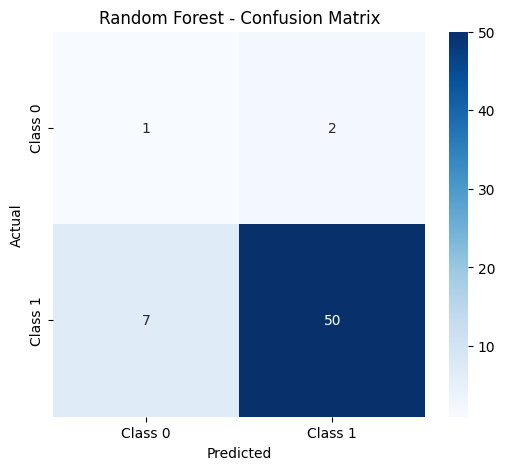

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [58]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, f1_score, recall_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

# Prepare data
model_df["month"] = pd.to_datetime(model_df["date"]).dt.month

features = [
    "rainfall_mm",
    "mean_temperature",
    "et0_mm",
    "water_balance_mm",
    "month"
]

data = model_df[features + ["target_next_month"]].dropna()

X = data[features]
y = data["target_next_month"].astype(int)

# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "macro_f1": make_scorer(f1_score, average="macro"),
    "class_0_recall": make_scorer(recall_score, pos_label=0)
}

models = {
    "Random Forest": Pipeline([
        ("balance", RandomOverSampler(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=3,
            random_state=42
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("balance", RandomOverSampler(random_state=42)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ])
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model, X, y,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Macro F1": scores["test_macro_f1"].mean(),
        "Class 0 Recall": scores["test_class_0_recall"].mean()
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

                 Model  Macro F1  Class 0 Recall
0        Random Forest     0.570           0.333
1  Logistic Regression     0.609           0.867


In [59]:
import joblib
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("balance", RandomOverSampler(random_state=42)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

final_model.fit(X, y)

joblib.dump(final_model, "crosafe_drought_model.pkl")

print("CroSafe drought model saved successfully!")

CroSafe drought model saved successfully!


In [60]:
import joblib
import json

joblib.dump(final_model, "crosafe_logistic_model.pkl")

results_summary = {
    "selected_model": "Logistic Regression",
    "macro_f1": 0.609,
    "class_0_recall": 0.867,
    "data_location": "Damascus",
    "prediction_target": "target_next_month",
    "status": "Experimental - not production validated"
}

with open("crosafe_model_results.json", "w") as f:
    json.dump(results_summary, f, indent=4)

print("Model and experiment results saved successfully!")

Model and experiment results saved successfully!


In [61]:
print("Available data:")
print([v for v in globals() if isinstance(v, pd.DataFrame)])

print("\nWeather columns:")
print(weather_df.columns.tolist())

print("\nMonthly columns:")
print(monthly_df.columns.tolist())

Available data:
[]

Weather columns:
['date', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'et0_fao_evapotranspiration', 'year', 'month']

Monthly columns:
['date', 'rainfall_mm', 'mean_temperature', 'et0_mm', 'water_balance_mm', 'water_deficit', 'year']


In [66]:
!pip -q install xclim

In [69]:
import xclim

print("Location:", getattr(xclim, "file", None))
print("Package paths:", getattr(xclim, "path", None))
!pip show xclim

Location: None
Package paths: None
Name: xclim
Version: 1.0.1
Summary: Climate indices computation package based on Xarray.
Home-page: https://xclim.readthedocs.io/
Author: 
Author-email: Travis Logan <logan.travis@ouranos.ca>
License-Expression: Apache-2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: boltons, cf-xarray, cftime, click, dask, docstring_parser, filelock, numba, numbagg, numpy, packaging, pandas, pint, pyarrow, pyyaml, scikit-learn, scipy, xarray, yamale
Required-by: 


In [70]:
!pip uninstall -y xclim
!pip install --no-cache-dir xclim

Found existing installation: xclim 1.0.1
Uninstalling xclim-1.0.1:
  Successfully uninstalled xclim-1.0.1


In [6]:
import pandas as pd
import numpy as np

# 1. Reload original CSV
weather_df = pd.read_csv(
    "/content/damascus_weather_2001_2025.csv"
)

# 2. Remove duplicate column names
weather_df = weather_df.loc[
    :, ~weather_df.columns.duplicated()
].copy()

weather_df.columns = weather_df.columns.str.strip()

# 3. Convert date safely
date_values = weather_df["date"].astype(str).str.strip()

weather_df["date"] = pd.to_datetime(
    date_values,
    errors="coerce",
    utc=True
).dt.tz_localize(None)

weather_df = weather_df.dropna(subset=["date"]).copy()

# 4. Convert numeric columns
numeric_cols = [
    "precipitation_sum",
    "temperature_2m_mean",
    "et0_fao_evapotranspiration"
]

for col in numeric_cols:
    weather_df[col] = pd.to_numeric(
        weather_df[col], errors="coerce"
    )

weather_df = weather_df.dropna(subset=numeric_cols)

# 5. Build monthly dataset
weather_df["month_period"] = (
    weather_df["date"].dt.to_period("M")
)

monthly_df = weather_df.groupby("month_period").agg(
    rainfall_mm=("precipitation_sum", "sum"),
    mean_temperature=("temperature_2m_mean", "mean"),
    et0_mm=("et0_fao_evapotranspiration", "sum")
).reset_index()

monthly_df["date"] = (
    monthly_df["month_period"].dt.to_timestamp()
)

monthly_df = monthly_df.drop(columns=["month_period"])

# 6. Calculate water balance
monthly_df["year"] = monthly_df["date"].dt.year

monthly_df["water_balance_mm"] = (
    monthly_df["rainfall_mm"] - monthly_df["et0_mm"]
)

monthly_df["water_deficit"] = (
    monthly_df["water_balance_mm"] < 0
).astype(int)

# 7. Verify
print("SUCCESS")
print("Daily records:", len(weather_df))
print("Monthly records:", len(monthly_df))
print("Date range:", monthly_df["date"].min(),
      "to", monthly_df["date"].max())
print("Date type:", weather_df["date"].dtype)

display(monthly_df.head())

SUCCESS
Daily records: 9131
Monthly records: 301
Date range: 2000-12-01 00:00:00 to 2025-12-01 00:00:00
Date type: datetime64[ns]


,rainfall_mm,mean_temperature,et0_mm,date,year,water_balance_mm,water_deficit
0,0.000000,6.997333,1.737162,2000-12-01,2000,-1.737162,1
1,13.500000,6.554255,53.655408,2001-01-01,2001,-40.155408,1
2,44.800001,7.507378,59.670234,2001-02-01,2001,-14.870234,1
3,6.400000,14.628987,125.601529,2001-03-01,2001,-119.201529,1
4,4.500000,17.105737,153.087745,2001-04-01,2001,-148.587744,1


In [7]:
from scipy.stats import fisk, norm
import numpy as np
import pandas as pd

# 1. Prepare monthly water balance
spei_df = monthly_df.copy()
spei_df["date"] = pd.to_datetime(spei_df["date"])
spei_df = spei_df.sort_values("date").reset_index(drop=True)

# 2. Calculate 3-month accumulated water balance
spei_df["wb_3"] = (
    spei_df["water_balance_mm"]
    .rolling(window=3, min_periods=3)
    .sum()
)

# 3. Extract calendar month
spei_df["month"] = spei_df["date"].dt.month
spei_df["spei_3"] = np.nan

# 4. Fit log-logistic distribution for each calendar month
for month in range(1, 13):
    mask = (
        (spei_df["month"] == month) &
        spei_df["wb_3"].notna()
    )

    values = spei_df.loc[mask, "wb_3"].values

    if len(values) < 15:
        continue

    params = fisk.fit(values)
    probabilities = fisk.cdf(values, *params)

    probabilities = np.clip(
        probabilities, 0.0001, 0.9999
    )

    spei_df.loc[mask, "spei_3"] = norm.ppf(probabilities)

# 5. Classify drought severity
def classify_drought(value):
    if pd.isna(value):
        return "Unknown"
    elif value <= -2:
        return "Extreme drought"
    elif value <= -1.5:
        return "Severe drought"
    elif value <= -1:
        return "Moderate drought"
    elif value <= -0.5:
        return "Mild drought"
    else:
        return "No significant drought"

spei_df["drought_status"] = spei_df["spei_3"].apply(
    classify_drought
)

# 6. Display results
print("SPEI-3 calculation completed")
print("Valid SPEI records:", spei_df["spei_3"].notna().sum())
print("\nDrought categories:")
print(spei_df["drought_status"].value_counts())

display(
    spei_df[
        ["date", "rainfall_mm", "et0_mm",
         "wb_3", "spei_3", "drought_status"]
    ].tail(15)
)

SPEI-3 calculation completed
Valid SPEI records: 299

Drought categories:
drought_status
No significant drought    287
Extreme drought            12
Unknown                     2
Name: count, dtype: int64


,date,rainfall_mm,et0_mm,wb_3,spei_3,drought_status
286,2024-10-01,0.400000,127.442991,-540.710674,0.625527,No significant drought
287,2024-11-01,8.600000,73.447421,-367.736101,0.221435,No significant drought
288,2024-12-01,13.500001,57.647570,-236.037980,-0.068315,No significant drought
289,2025-01-01,0.800000,63.044518,-171.239508,-3.719016,Extreme drought
290,2025-02-01,10.900000,66.343459,-161.835545,-3.719016,Extreme drought
291,2025-03-01,21.400000,119.452203,-215.740180,0.047770,No significant drought
292,2025-04-01,11.400000,159.724092,-301.819754,0.751692,No significant drought
293,2025-05-01,1.900000,216.696514,-461.172810,0.829175,No significant drought
294,2025-06-01,0.000000,233.331077,-596.451684,0.780593,No significant drought
295,2025-07-01,0.000000,257.185495,-705.313087,0.781610,No significant drought


In [9]:
print("monthly_df columns:")
print(monthly_df.columns.tolist())

print("\nLast calculated SPEI table:")
print(spei_df.columns.tolist())

monthly_df columns:
['rainfall_mm', 'mean_temperature', 'et0_mm', 'date', 'year', 'water_balance_mm', 'water_deficit']

Last calculated SPEI table:
['rainfall_mm', 'mean_temperature', 'et0_mm', 'date', 'year', 'water_balance_mm', 'water_deficit', 'wb_3', 'month', 'spei_3', 'drought_status']


In [10]:
print("SPEI-3 statistics:")
print(spei_df["spei_3"].describe())

print("\nDrought categories:")
print(spei_df["drought_status"].value_counts(dropna=False))

print("\nWater balance statistics:")
print(spei_df["wb_3"].describe())

SPEI-3 statistics:
count    299.000000
mean       0.730871
std        0.926981
min       -3.719016
25%        0.827990
50%        0.948153
75%        1.009776
max        1.259142
Name: spei_3, dtype: float64

Drought categories:
drought_status
No significant drought    287
Extreme drought            12
Unknown                     2
Name: count, dtype: int64

Water balance statistics:
count    299.000000
mean    -375.054257
std      226.196247
min     -775.494950
25%     -600.484923
50%     -366.604426
75%     -166.215442
max       69.280393
Name: wb_3, dtype: float64


In [11]:
# 1. Prepare data for drought prediction

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_df = spei_df.copy()
model_df["date"] = pd.to_datetime(model_df["date"])
model_df = model_df.sort_values("date").reset_index(drop=True)

# Use previous months to predict next month's SPEI-3
model_df["rainfall_lag1"] = model_df["rainfall_mm"].shift(1)
model_df["temperature_lag1"] = model_df["mean_temperature"].shift(1)
model_df["et0_lag1"] = model_df["et0_mm"].shift(1)
model_df["spei_lag1"] = model_df["spei_3"].shift(1)
model_df["spei_lag2"] = model_df["spei_3"].shift(2)
model_df["spei_lag3"] = model_df["spei_3"].shift(3)

# Target: next month's SPEI-3
model_df["target_spei"] = model_df["spei_3"].shift(-1)

features = [
    "rainfall_lag1",
    "temperature_lag1",
    "et0_lag1",
    "spei_lag1",
    "spei_lag2",
    "spei_lag3"
]

model_df = model_df.dropna(subset=features + ["target_spei"])

X = model_df[features]
y = model_df["target_spei"]

# Chronological split: first 80% for training, last 20% for testing
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Target: Next month's SPEI-3")

Training records: 236
Testing records: 59
Target: Next month's SPEI-3


In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create and train the model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("random_forest", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_split=4,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

# Predict test data
predictions = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MODEL PERFORMANCE")
print("-----------------")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MODEL PERFORMANCE
-----------------
Training records: 236
Testing records: 59
MAE: 0.91
RMSE: 1.618
R2 Score: -0.223


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline = np.full(len(y_test), y_train.mean())

print("Baseline MAE:", round(mean_absolute_error(y_test, baseline), 3))
print("Model MAE:", round(mean_absolute_error(y_test, predictions), 3))

print("Baseline R2:", round(r2_score(y_test, baseline), 3))
print("Model R2:", round(r2_score(y_test, predictions), 3))

Baseline MAE: 0.671
Model MAE: 0.91
Baseline R2: -0.182
Model R2: -0.223


In [17]:
print("Features used:")
print(X_train.columns.tolist())

print("\nTraining target:")
print(y_train.describe())

print("\nTesting target:")
print(y_test.describe())

Features used:
['rainfall_lag1', 'temperature_lag1', 'et0_lag1', 'spei_lag1', 'spei_lag2', 'spei_lag3']

Training target:
count    236.000000
mean       0.853536
std        0.688240
min       -3.719016
25%        0.912445
50%        0.964614
75%        1.023881
max        1.259142
Name: target_spei, dtype: float64

Testing target:
count    59.000000
mean      0.229769
std       1.475499
min      -3.719016
25%       0.670352
50%       0.780593
75%       0.872048
max       1.084449
Name: target_spei, dtype: float64


In [18]:
from sklearn.metrics import mean_absolute_error, r2_score

# توقع الشهر القادم باستخدام قيمة SPEI السابقة
persistence_predictions = X_test["spei_lag1"]

# تقييم التوقع البسيط
persistence_mae = mean_absolute_error(
    y_test, persistence_predictions
)

persistence_r2 = r2_score(
    y_test, persistence_predictions
)

# مقارنة النموذج الحالي بالتوقع البسيط
print("MODEL COMPARISON")
print("-------------------------")
print("Our Model MAE:", round(mae, 3))
print("Previous SPEI MAE:", round(persistence_mae, 3))
print()
print("Our Model R2:", round(r2, 3))
print("Previous SPEI R2:", round(persistence_r2, 3))

MODEL COMPARISON
-------------------------
Our Model MAE: 0.91
Previous SPEI MAE: 0.974

Our Model R2: -0.223
Previous SPEI R2: -0.726


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

improved_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=4,
    min_samples_split=8,
    min_samples_leaf=4,
    max_features=0.8,
    random_state=42
)

improved_model.fit(X_train, y_train)

improved_predictions = improved_model.predict(X_test)

improved_mae = mean_absolute_error(
    y_test, improved_predictions
)

improved_r2 = r2_score(
    y_test, improved_predictions
)

print("IMPROVED RANDOM FOREST")
print("----------------------")
print("MAE:", round(improved_mae, 3))
print("R2:", round(improved_r2, 3))

IMPROVED RANDOM FOREST
----------------------
MAE: 0.791
R2: -0.101


In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

results = []

settings = [
    {"n_estimators": 300, "max_depth": 3, "min_samples_split": 5, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 500, "max_depth": 5, "min_samples_split": 5, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 500, "max_depth": 7, "min_samples_split": 8, "min_samples_leaf": 3, "max_features": 1.0},
    {"n_estimators": 700, "max_depth": 4, "min_samples_split": 10, "min_samples_leaf": 4, "max_features": 0.8},
    {"n_estimators": 300, "max_depth": None, "min_samples_split": 10, "min_samples_leaf": 5, "max_features": 0.8}
]

for params in settings:
    candidate = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    candidate.fit(X_train, y_train)
    pred = candidate.predict(X_test)

    results.append({
        "Settings": str(params),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

comparison_df = pd.DataFrame(results).sort_values("MAE")

print(comparison_df.to_string(index=False))

                                                                                                     Settings      MAE        R2
{'n_estimators': 300, 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.8} 0.775312 -0.097541
   {'n_estimators': 700, 'max_depth': 4, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.8} 0.790766 -0.100693
    {'n_estimators': 300, 'max_depth': 3, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 1.0} 0.862767 -0.161992
    {'n_estimators': 500, 'max_depth': 7, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 1.0} 0.872566 -0.174521
    {'n_estimators': 500, 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 1.0} 0.896405 -0.191068


FEATURE IMPORTANCE:
spei_lag1           0.310046
spei_lag3           0.284842
temperature_lag1    0.197455
spei_lag2           0.086896
et0_lag1            0.061085
rainfall_lag1       0.059677
dtype: float64


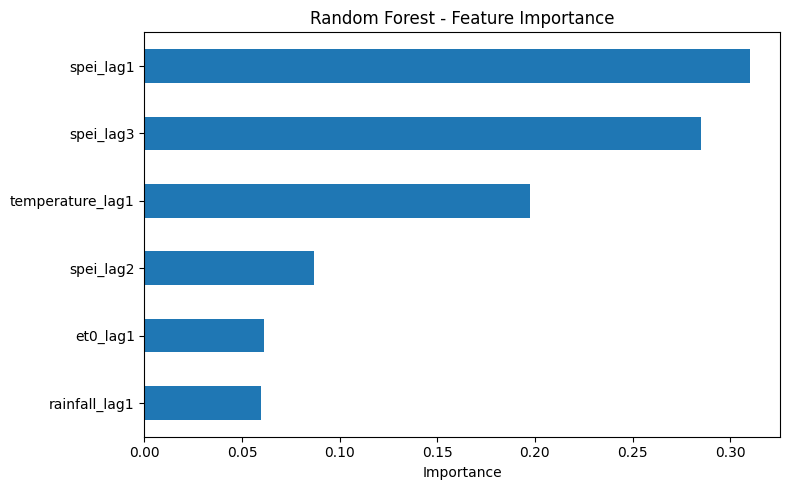

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    improved_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

print("FEATURE IMPORTANCE:")
print(importance.sort_values(ascending=False))

importance.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import mean_absolute_error, r2_score

# Best Random Forest
best_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)
best_predictions = best_model.predict(X_test)

# Persistence baseline: previous month's SPEI
baseline_predictions = X_test["spei_lag1"]

print("MODEL vs BASELINE")
print("-----------------")

print("Random Forest MAE:",
      round(mean_absolute_error(y_test, best_predictions), 3))

print("Previous SPEI MAE:",
      round(mean_absolute_error(y_test, baseline_predictions), 3))

print("Random Forest R2:",
      round(r2_score(y_test, best_predictions), 3))

print("Previous SPEI R2:",
      round(r2_score(y_test, baseline_predictions), 3))

MODEL vs BASELINE
-----------------
Random Forest MAE: 0.775
Previous SPEI MAE: 0.974
Random Forest R2: -0.098
Previous SPEI R2: -0.726


In [25]:
city_df = city_df.reset_index()

# Convert date column safely
date_values = city_df["date"].astype(str).str.strip()

if date_values.str.fullmatch(r"\d{6}").all():
    city_df["date"] = pd.to_datetime(
        date_values, format="%Y%m", errors="coerce"
    )
else:
    city_df["date"] = pd.to_datetime(
        date_values, errors="coerce"
    )

# Remove invalid dates and sort
city_df = city_df.dropna(subset=["date"])
city_df = city_df.sort_values("date").reset_index(drop=True)

print("Date conversion completed")
print(city_df[["date"]].head())
print("Rows:", len(city_df))

Date conversion completed
        date
0 2001-01-01
1 2001-02-01
2 2001-03-01
3 2001-04-01
4 2001-05-01
Rows: 300


In [26]:
print("Columns:")
print(city_df.columns.tolist())

print("\nFirst 5 rows:")
display(city_df.head())

print("\nDate range:")
print(city_df["date"].min(), "to", city_df["date"].max())

print("\nMissing values:")
print(city_df.isnull().sum())

Columns:
['index', 'date', 'ALLSKY_SFC_SW_DWN', 'PRECTOTCORR', 'RH2M', 'T2M', 'WS2M']

First 5 rows:


,index,date,ALLSKY_SFC_SW_DWN,PRECTOTCORR,RH2M,T2M,WS2M
0,0,2001-01-01,11.09,0.77,68.82,5.62,1.79
1,1,2001-02-01,13.21,2.47,74.32,5.82,2.95
2,2,2001-03-01,20.59,0.44,55.70,12.69,2.21
3,3,2001-04-01,23.14,0.19,52.00,14.65,2.58
4,4,2001-05-01,26.85,0.40,46.85,18.36,2.66



Date range:
2001-01-01 00:00:00 to 2025-12-01 00:00:00

Missing values:
index                0
date                 0
ALLSKY_SFC_SW_DWN    0
PRECTOTCORR          0
RH2M                 0
T2M                  0
WS2M                 0
dtype: int64


In [27]:
# Prepare dates in both datasets
city_df["date"] = pd.to_datetime(city_df["date"])
monthly_df["date"] = pd.to_datetime(monthly_df["date"])

# Remove unnecessary index column
city_df = city_df.drop(columns=["index"], errors="ignore")

# Rename NASA columns to clear names
city_df = city_df.rename(columns={
    "PRECTOTCORR": "rainfall_nasa_mm",
    "T2M": "temperature_nasa_c",
    "RH2M": "humidity_pct",
    "WS2M": "wind_speed_ms",
    "ALLSKY_SFC_SW_DWN": "solar_radiation"
})

# Merge the original weather data with NASA data
merged_df = pd.merge(
    monthly_df,
    city_df,
    on="date",
    how="inner",
    validate="one_to_one"
)

# Check the merged dataset
print("Merged data shape:", merged_df.shape)
print("\nColumns:")
print(merged_df.columns.tolist())

print("\nMissing values:")
print(merged_df.isnull().sum())

display(merged_df.head())

Merged data shape: (300, 12)

Columns:
['rainfall_mm', 'mean_temperature', 'et0_mm', 'date', 'year', 'water_balance_mm', 'water_deficit', 'solar_radiation', 'rainfall_nasa_mm', 'humidity_pct', 'temperature_nasa_c', 'wind_speed_ms']

Missing values:
rainfall_mm           0
mean_temperature      0
et0_mm                0
date                  0
year                  0
water_balance_mm      0
water_deficit         0
solar_radiation       0
rainfall_nasa_mm      0
humidity_pct          0
temperature_nasa_c    0
wind_speed_ms         0
dtype: int64


,rainfall_mm,mean_temperature,et0_mm,date,year,water_balance_mm,water_deficit,solar_radiation,rainfall_nasa_mm,humidity_pct,temperature_nasa_c,wind_speed_ms
0,13.500000,6.554255,53.655408,2001-01-01,2001,-40.155408,1,11.09,0.77,68.82,5.62,1.79
1,44.800001,7.507378,59.670234,2001-02-01,2001,-14.870234,1,13.21,2.47,74.32,5.82,2.95
2,6.400000,14.628987,125.601529,2001-03-01,2001,-119.201529,1,20.59,0.44,55.70,12.69,2.21
3,4.500000,17.105737,153.087745,2001-04-01,2001,-148.587744,1,23.14,0.19,52.00,14.65,2.58
4,5.600000,20.526299,183.093785,2001-05-01,2001,-177.493785,1,26.85,0.40,46.85,18.36,2.66


In [28]:
import os
import glob

files = glob.glob("/content/**/*.csv", recursive=True)

print("CSV files found:")
for f in files:
    print(os.path.basename(f))

CSV files found:
POWER_Regional_Monthly_2000_2025 (2).csv
POWER_Regional_Monthly_2000_2025 (1).csv
damascus_weather_2001_2025.csv
POWER_Regional_Monthly_2000_2025 (3).csv
POWER_Regional_Monthly_2000_2025.csv
california_housing_train.csv
mnist_test.csv
mnist_train_small.csv
california_housing_test.csv


In [30]:
import glob
import os

files = sorted(glob.glob(
    "/content/POWER_Regional_Monthly_2000_2025*.csv"
))

for file in files:
    print("\n" + "=" * 60)
    print("FILE:", os.path.basename(file))

    with open(file, "r", encoding="utf-8-sig") as f:
        for i in range(15):
            line = f.readline()
            if not line:
                break
            print(i, repr(line.strip()))


FILE: POWER_Regional_Monthly_2000_2025 (1).csv
0 '-BEGIN HEADER-'
1 'NASA/POWER Source Native Resolution Monthly and Annual'
2 'Dates (month/day/year): 01/01/2000 through 12/31/2025 in LST'
3 'Location: Regional'
4 'Elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = na meters'
5 'The value for missing source data that cannot be computed or is outside of the sources availability range: -999'
6 'Parameter(s):'
7 'ALLSKY_SFC_SW_DWN     CERES SYN1deg All Sky Surface Shortwave Downward Irradiance (MJ/m^2/day)'
8 '-END HEADER-'
9 'PARAMETER,YEAR,LAT,LON,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANN'
10 'ALLSKY_SFC_SW_DWN,2000,33.5,36.5,9.84,15.04,18.82,22.15,28.26,29.99,29.08,27.02,23.61,16.19,12.72,10.25,20.26'
11 'ALLSKY_SFC_SW_DWN,2000,33.5,37.5,11.35,16.24,19.72,22.96,28.47,30.61,29.28,26.8,22.14,16.38,12.08,10.53,20.55'
12 'ALLSKY_SFC_SW_DWN,2000,33.5,38.5,11.39,16.82,20.03,23.67,28.46,29.91,29.31,27.01,23.12,16.69,12.46,10.32,20.77'
13 'ALLSKY_SFC_SW_DWN,200

In [31]:
import pandas as pd
import glob
import os

# أسماء الأشهر
months = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

files = glob.glob(
    "/content/POWER_Regional_Monthly_2000_2025*.csv"
)

all_data = []

for file in files:
    # تخطي الترويسة وقراءة الجدول الحقيقي
    df = pd.read_csv(file, skiprows=9)

    # إزالة المسافات من أسماء الأعمدة
    df.columns = df.columns.str.strip()

    # تحويل البيانات من أعمدة الأشهر إلى صفوف
    long_df = df.melt(
        id_vars=["PARAMETER", "YEAR", "LAT", "LON"],
        value_vars=months,
        var_name="month",
        value_name="value"
    )

    # إنشاء التاريخ
    month_numbers = {
        name: number
        for number, name in enumerate(months, start=1)
    }

    long_df["month_number"] = long_df["month"].map(month_numbers)

    long_df["date"] = pd.to_datetime(
        dict(
            year=long_df["YEAR"],
            month=long_df["month_number"],
            day=1
        )
    )

    long_df["value"] = pd.to_numeric(
        long_df["value"], errors="coerce"
    )

    long_df.loc[long_df["value"] == -999, "value"] = float("nan")

    all_data.append(
        long_df[["date", "LAT", "LON", "PARAMETER", "value"]]
    )

# دمج جميع المتغيرات حسب الموقع والتاريخ
combined_df = pd.concat(all_data, ignore_index=True)

combined_df = combined_df.pivot_table(
    index=["date", "LAT", "LON"],
    columns="PARAMETER",
    values="value"
).reset_index()

combined_df.columns.name = None

print("Shape:", combined_df.shape)
print("Columns:", combined_df.columns.tolist())
display(combined_df.head())

print("\nMissing values:")
print(combined_df.isnull().sum())

Shape: (39000, 7)
Columns: ['date', 'LAT', 'LON', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'T2M', 'WS2M']


,date,LAT,LON,ALLSKY_SFC_SW_DWN,RH2M,T2M,WS2M
0,2000-01-01,33.0,36.250,NaN,70.83,6.68,3.25
1,2000-01-01,33.0,36.875,NaN,67.17,5.53,3.96
2,2000-01-01,33.0,37.500,NaN,63.47,6.31,3.36
3,2000-01-01,33.0,38.125,NaN,64.14,5.54,3.42
4,2000-01-01,33.0,38.750,NaN,62.03,5.40,3.42



Missing values:
date                     0
LAT                      0
LON                      0
ALLSKY_SFC_SW_DWN    29640
RH2M                  7800
T2M                   7800
WS2M                  7800
dtype: int64


In [32]:
# فحص القيم المفقودة حسب السنة
missing_by_year = (
    combined_df
    .assign(year=combined_df["date"].dt.year)
    .groupby("year")
    [["ALLSKY_SFC_SW_DWN", "RH2M", "T2M", "WS2M"]]
    .agg(lambda x: x.isna().sum())
)

print("Missing values by year:")
display(missing_by_year)

# نسبة توفر كل متغير
print("\nAvailability percentage:")
availability = (
    combined_df[
        ["ALLSKY_SFC_SW_DWN", "RH2M", "T2M", "WS2M"]
    ].notna().mean() * 100
)

display(availability.round(2))

Missing values by year:


,ALLSKY_SFC_SW_DWN,RH2M,T2M,WS2M
year,,,,
2000,1140,300,300,300
2001,1140,300,300,300
2002,1140,300,300,300
2003,1140,300,300,300
2004,1140,300,300,300
2005,1140,300,300,300
2006,1140,300,300,300
2007,1140,300,300,300
2008,1140,300,300,300



Availability percentage:


,0
ALLSKY_SFC_SW_DWN,24.0
RH2M,80.0
T2M,80.0
WS2M,80.0


In [35]:
print("Available data:")

names = [
    "monthly_df", "spei_df", "combined_df",
    "X_train", "X_test", "y_train", "y_test",
    "model", "best_model"
]

for name in names:
    if name in globals():
        obj = globals()[name]
        print(name, ":", obj.shape if hasattr(obj, "shape") else str(type(obj)))
    else:
        print(name, ": NOT FOUND")

Available data:
monthly_df : (301, 7)
spei_df : (301, 11)
combined_df : (39000, 7)
X_train : (236, 6)
X_test : (59, 6)
y_train : (236,)
y_test : (59,)
model : <class 'sklearn.pipeline.Pipeline'>
best_model : <class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [36]:
print("Model features:")
print(list(X_train.columns))

print("\nTarget:")
print(y_train.name)

print("\nModel parameters:")
print(best_model.get_params())

Model features:
['rainfall_lag1', 'temperature_lag1', 'et0_lag1', 'spei_lag1', 'spei_lag2', 'spei_lag3']

Target:
target_spei

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.8, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [37]:
import joblib
import json

# Save trained model
joblib.dump(best_model, "crosafe_drought_model.pkl")

# Save model information
model_info = {
    "model_name": "Random Forest Regressor",
    "target": "target_spei",
    "features": list(X_train.columns),
    "prediction": "Next month's SPEI-3",
    "n_estimators": 300,
    "max_depth": None,
    "min_samples_split": 10,
    "min_samples_leaf": 5,
    "max_features": 0.8,
    "random_state": 42
}

with open("crosafe_model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("Model saved successfully!")
print("Files:")
print("- crosafe_drought_model.pkl")
print("- crosafe_model_info.json")

Model saved successfully!
Files:
- crosafe_drought_model.pkl
- crosafe_model_info.json
